# 3장 2강 종합 분석 실습: 퍼널·리텐션·개선 시나리오 통합 적용

**파일 구분: 정답 및 해설**

## 실습 목표

- Ravenstack의 실제 기록으로 시간순 퍼널과 가입 월별 리텐션을 계산한다.
- 전환율·리텐션 표와 그래프를 근거로 초기 가설을 검토한다.
- 교안의 네 가지 기준으로 개선 우선순위를 정한다.
- 이상 신호 → 개선안 → 기대 효과 → A/B 테스트 아이디어를 작성한다.

## 실습 환경 / 데이터

- Python / Colab, pandas, matplotlib. 필요 시 `%pip install pandas matplotlib`를 별도 셀에서 실행합니다.
- 첨부 Ravenstack 중 `accounts`, `subscriptions`, `feature_usage` CSV를 사용합니다. `(2)`가 붙은 파일명과 원래 파일명을 모두 지원합니다.
- `support_tickets`, `churn_events`도 제공된 동일 데이터셋의 일부지만 이번 교안의 퍼널·기능 사용 리텐션 계산에는 필요하지 않아 분석에 사용하지 않습니다.
- CSV를 노트북과 같은 폴더에 두거나 준비 코드의 `DATA_DIR`을 수정하세요.

### 분석 문제와 공통 기준

이번 실습은 **2024년 7~9월 가입한 전체 산업의 신규 계정**을 대상으로 합니다. 기존 파일의 DevTools 구독 상태 비교를, 교안의 가입 시점·시간순 행동 분석에 맞게 변경했습니다. 별도의 1강 답안 없이도 풀 수 있도록 문제와 가설을 아래에 제공합니다.

- 분석 문제: 신규 계정은 가입한 달에 기능 사용까지 얼마나 도달하며, 이후에도 사용하는가?
- 목표 지표: 가입 월 기능 사용 도달률 = 가입 월에 실제 사용한 계정 수 / 대상 가입 계정 수.
- 초기 가설: 가입→구독 시작보다 구독 시작→기능 사용 구간의 전환율이 낮을 것이다. 이후 기능 사용률은 매월 감소할 것이다. **분석 전 가설이며 실제 결과와 다를 수 있습니다.**
- 분석 단위는 `account_id`입니다. 한 계정의 여러 구독·사용 기록은 중복 계정으로 세지 않습니다.
- 실제 사용은 `usage_count > 0`, 사용일이 해당 구독 시작일 이상이며 종료일이 있으면 종료일 이하인 기록입니다. 가입 전 시작된 구독은 이 신규 가입 경로에서 제외합니다.
- 달은 달력 월입니다. 가입 월 말까지를 퍼널 관찰 기간으로 사용하므로 월말 가입자는 관찰 일수가 짧습니다. 동일한 가입 후 30일 지표와는 다릅니다.
- 파일의 최종 사용일을 분석 종료일로 사용하며, 그때까지의 로그가 제공되었다고 가정합니다. 로그가 없다는 것은 기록상 미사용이며 해지·영구 이탈을 뜻하지 않습니다.

| 컬럼 | 활용 |
|---|---|
| accounts: account_id, signup_date | 신규 계정과 가입 월 코호트 |
| subscriptions: subscription_id, account_id, start_date, end_date | 가입 이후 구독 시작 확인, 계정과 사용 기록 연결 |
| feature_usage: subscription_id, usage_date, usage_count | 실제 기능 사용과 사용 월 확인 |

| 구성 | 교안에 대응하는 내용 |
|---|---|
| 필수 1 | 1절: 시간순 퍼널, 전환율, 시각화, 가설 대조 |
| 필수 2 | 2절: 가입 월 코호트, 리텐션 곡선과 변화 해석 |
| 과제 1 | 3·4절: 네 기준의 우선순위 판단과 네 항목의 개선 시나리오 |

## 실습 준비

아래 코드는 공통으로 제공합니다. 데이터 불러오기, 분석 컬럼·결측치·자료형, 기초 통계량·분포를 확인하고 분석용 표를 준비하세요. 테이블 연결은 Ravenstack 구조에 맞춘 준비 과정이며 새로운 통계 기법을 요구하지 않습니다.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path(".")
folders = [DATA_DIR, Path("upload"), Path("data"), Path("/content")]
data = {}
for name in ["accounts", "subscriptions", "feature_usage"]:
    names = [f"ravenstack_{name}(2).csv", f"ravenstack_{name}.csv"]
    path = next((d/f for f in names for d in folders if (d/f).exists()), None)
    if path is None:
        raise FileNotFoundError(f"{name} CSV를 올리거나 DATA_DIR을 수정하세요.")
    data[name] = pd.read_csv(path)
    print(path.name, data[name].shape)

accounts = data["accounts"][["account_id", "signup_date"]].copy()
subscriptions = data["subscriptions"][["subscription_id", "account_id", "start_date", "end_date"]].copy()
usage = data["feature_usage"][["subscription_id", "usage_date", "usage_count"]].copy()
for frame, cols in [(accounts, ["signup_date"]), (subscriptions, ["start_date", "end_date"]), (usage, ["usage_date"])]:
    for col in cols:
        frame[col] = pd.to_datetime(frame[col], errors="raise")
    print("\n분석 컬럼 예시:\n", frame.head(3).to_string(index=False))
    print("자료형:\n", frame.dtypes.to_string())
    print("결측치:\n", frame.isna().sum().to_string())
# end_date 결측은 종료일이 기록되지 않은 구독이므로 삭제하지 않습니다.
assert accounts.account_id.is_unique
assert subscriptions.subscription_id.is_unique
assert not accounts.isna().any().any()
assert not subscriptions.drop(columns="end_date").isna().any().any()
assert not usage.isna().any().any()
print("\n사용 횟수 기초 통계량:\n", usage.usage_count.describe().to_string())
print("가입 월별 계정 수:\n", accounts.groupby(accounts.signup_date.dt.to_period("M")).size().to_string())
analysis_end = usage.usage_date.max()
print("사용 기록 범위:", usage.usage_date.min().date(), "~", analysis_end.date())

target = accounts.loc[accounts.signup_date.between("2024-07-01", "2024-09-30")].copy()
target["cohort"] = target.signup_date.dt.to_period("M")
subs = subscriptions.merge(target, on="account_id", how="inner", validate="many_to_one")
excluded_subs = (subs.start_date < subs.signup_date).sum()
subs = subs.loc[subs.start_date >= subs.signup_date].copy()
events = usage.merge(subs, on="subscription_id", how="inner", validate="many_to_one")
valid = ((events.usage_count > 0) & (events.usage_date >= events.start_date)
         & (events.end_date.isna() | (events.usage_date <= events.end_date)))
excluded_events = (~valid).sum()
events = events.loc[valid].copy()
events["month_offset"] = ((events.usage_date.dt.year - events.signup_date.dt.year) * 12
                          + events.usage_date.dt.month - events.signup_date.dt.month)
print("\n대상 신규 계정 수:", len(target))
print("가입 전 시작으로 제외한 구독 수:", excluded_subs)
print("사용 조건을 충족하지 않아 제외한 연결 기록 수:", excluded_events)
print("코호트별 가입 계정 수:\n", target.groupby("cohort").size().to_string())

ravenstack_accounts.csv (500, 10)
ravenstack_subscriptions.csv (5000, 14)
ravenstack_feature_usage.csv (25000, 8)

분석 컬럼 예시:
 account_id signup_date
  A-2e4581  2024-10-16
  A-43a9e3  2023-08-17
  A-0a282f  2024-08-27
자료형:
 account_id                str
signup_date    datetime64[us]
결측치:
 account_id     0
signup_date    0

분석 컬럼 예시:
 subscription_id account_id start_date   end_date
       S-8cec59   A-3c1a3f 2023-12-23 2024-04-12
       S-0f6f44   A-9b9fe9 2024-06-11        NaT
       S-51c0d1   A-659280 2024-11-25        NaT
자료형:
 subscription_id               str
account_id                    str
start_date         datetime64[us]
end_date           datetime64[us]
결측치:
 subscription_id       0
account_id            0
start_date            0
end_date           4514

분석 컬럼 예시:
 subscription_id usage_date  usage_count
       S-0fcf7d 2023-07-27            9
       S-c25263 2023-08-07            9
       S-f29e7f 2023-12-07            9
자료형:
 subscription_id               str
usage_date  

---

## 필수 1 — 신규 계정의 가입 월 퍼널 분석

### 상황

가입한 달에 기능 사용까지 도달하지 못하는 구간을 찾으려고 합니다. 실제 데이터에 없는 화면 조회·온보딩 이벤트는 만들지 않습니다.

### 수행 사항

1. `target`, `subs`, `events`로 아래 세 단계의 고유 계정 수를 계산하세요.
   - 가입: 대상 계정 전체
   - 구독 시작: 가입일 이후이면서 가입 월 안에 구독이 시작된 계정
   - 기능 사용: 해당 구독에서 가입 월 안에 실제 사용한 계정
2. 이전 단계 대비 전환율·이탈률과 미도달 계정 수를 표로 만드세요. 첫 단계의 전환율·이탈률은 비교 대상이 없어 빈 값으로 둡니다.
3. 막대그래프로 단계별 계정 수를 표시하고 가장 낮은 전환율 구간을 찾으세요.
4. 가입 월 기능 사용 도달률도 계산하여 초기 가설과 대조하세요.

### 질문

Q1. 세 단계의 계정 수와 구간별 전환율·이탈률·미도달 수는 얼마인가요?

Q2. 가장 낮은 전환율 구간은 어디이며, 퍼널 초기 가설과 일치하나요?

Q3. 가입 월 기능 사용 도달률은 얼마이며, 마지막 구간 전환율과 분모가 어떻게 다른가요?

Q4. 왜 계정 수를 중복 제거해야 하며, 이 결과만으로 미사용 원인을 확정할 수 있나요?

### 체크 포인트

같은 분석 단위, 시간 순서, 이전 단계 분모, 데이터로 확인한 사실과 원인 가설의 구분.

In [2]:
# 1) 단계별 고유 계정 집합 (시간 순서: 가입 → 가입 월 내 구독 시작 → 그 구독으로 가입 월 내 사용)
signup_ids = set(target.account_id)

subs_m0 = subs.loc[subs.start_date.dt.to_period("M") == subs.cohort]        # 가입 월 안에 시작한 구독
sub_ids = set(subs_m0.account_id)

events_m0 = events.loc[(events.month_offset == 0)
                       & events.subscription_id.isin(subs_m0.subscription_id)]  # 해당 구독의 가입 월 사용
use_ids = set(events_m0.account_id)
assert use_ids <= sub_ids <= signup_ids   # 이전 단계의 부분집합인지 확인

# 2) 퍼널 표
funnel = pd.DataFrame({
    "stage": ["가입", "구독 시작(가입 월)", "기능 사용(가입 월)"],
    "accounts": [len(signup_ids), len(sub_ids), len(use_ids)],
})
prev = funnel["accounts"].shift(1)
funnel["conversion_rate(%)"] = (funnel["accounts"] / prev * 100).round(1)
funnel["drop_rate(%)"] = (100 - funnel["conversion_rate(%)"]).round(1)
funnel["not_reached"] = (prev - funnel["accounts"]).astype("Int64")
display(funnel)   # 첫 단계는 비교 대상이 없어 NaN(빈 값)

lowest = funnel["conversion_rate(%)"].idxmin()
print(f"가장 낮은 전환율 구간: {funnel.stage[lowest-1]} → {funnel.stage[lowest]} "
      f"({funnel.loc[lowest, 'conversion_rate(%)']}%)")

# 4) 목표 지표: 가입 월 기능 사용 도달률 (분모 = 대상 가입 계정 전체)
reach_rate = len(use_ids) / len(signup_ids) * 100
print(f"가입 월 기능 사용 도달률: {len(use_ids)} / {len(signup_ids)} = {reach_rate:.1f}%")
print(f"마지막 구간 전환율:       {len(use_ids)} / {len(sub_ids)} = {len(use_ids)/len(sub_ids)*100:.1f}%")

# 참고: 코호트별 퍼널
by_cohort = target.groupby("cohort").account_id.apply(lambda s: pd.Series({
    "가입": len(s), "구독 시작": len(set(s) & sub_ids), "기능 사용": len(set(s) & use_ids)})).unstack()
display(by_cohort)

,stage,accounts,conversion_rate(%),drop_rate(%),not_reached
0,가입,72,NaN,NaN,<NA>
1,구독 시작(가입 월),52,72.2,27.8,20
2,기능 사용(가입 월),5,9.6,90.4,47


가장 낮은 전환율 구간: 구독 시작(가입 월) → 기능 사용(가입 월) (9.6%)
가입 월 기능 사용 도달률: 5 / 72 = 6.9%
마지막 구간 전환율:       5 / 52 = 9.6%


,가입,구독 시작,기능 사용
cohort,,,
2024-07,26,18,2
2024-08,21,13,1
2024-09,25,21,2


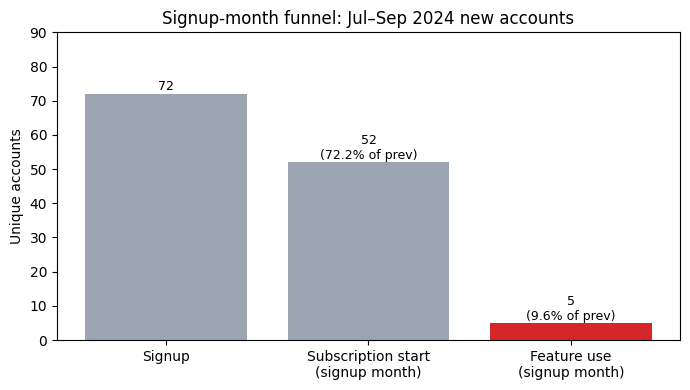

In [3]:
# 3) 단계별 계정 수 막대그래프
fig, ax = plt.subplots(figsize=(7, 4))
labels = ["Signup", "Subscription start\n(signup month)", "Feature use\n(signup month)"]
colors = ["#9aa5b1", "#9aa5b1", "#d62728"]
bars = ax.bar(labels, funnel["accounts"], color=colors)
for i, b in enumerate(bars):
    txt = f"{funnel.accounts[i]}"
    if i > 0:
        txt += f"\n({funnel['conversion_rate(%)'][i]}% of prev)"
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1, txt, ha="center", fontsize=9)
ax.set_title("Signup-month funnel: Jul–Sep 2024 new accounts")
ax.set_ylabel("Unique accounts")
ax.set_ylim(0, funnel.accounts.max() * 1.25)
plt.tight_layout()
plt.show()

In [4]:
# 추가 확인: 가입 월 안에서 구독 시작 후 남은 관찰 일수, 첫 사용 시점
first_sub = subs_m0.groupby("account_id").start_date.min()
days_left = (first_sub.dt.to_period("M").dt.end_time.dt.normalize() - first_sub).dt.days
print("가입 월 구독 시작 후 월말까지 남은 일수(중앙값):", int(days_left.median()), "일")

first_use_offset = events.groupby("account_id").month_offset.min()
print("관찰 종료일까지 한 번이라도 사용한 계정:", events.account_id.nunique(), "/", len(target))
print("첫 사용 월(M0=가입 월) 분포:")
print(first_use_offset.value_counts().sort_index().rename("accounts").to_string())

가입 월 구독 시작 후 월말까지 남은 일수(중앙값): 8 일
관찰 종료일까지 한 번이라도 사용한 계정: 69 / 72
첫 사용 월(M0=가입 월) 분포:
month_offset
0     5
1    23
2    24
3    12
4     4
5     1


### 서술 답안

**Q1.** 세 단계의 결과는 다음과 같습니다.

| 단계 | 계정 수 | 이전 단계 대비 전환율 | 이탈률 | 미도달 계정 |
|---|---:|---:|---:|---:|
| 가입 | 72 | - | - | - |
| 구독 시작(가입 월) | 52 | 72.2% | 27.8% | 20 |
| 기능 사용(가입 월) | 5 | **9.6%** | **90.4%** | **47** |

- 코호트별로 보면 7월 26→18→2, 8월 21→13→1, 9월 25→21→2입니다. 세 코호트 모두 같은 모양입니다.

**Q2.** 전환율이 가장 낮은 구간은 **구독 시작 → 기능 사용(9.6%)** 입니다.
- 가입 → 구독 시작(72.2%)보다 훨씬 낮으므로, "구독 시작 → 기능 사용 구간의 전환율이 더 낮을 것"이라는 **퍼널 초기 가설과 일치**합니다.
- 구독을 시작한 52개 계정 중 47개가 가입한 달 안에 한 번도 기능을 쓰지 않았습니다.

**Q3.** 가입 월 기능 사용 도달률은 **5 / 72 = 6.9%** 입니다.
- 도달률의 분모는 **대상 가입 계정 전체(72개)** 입니다.
- 마지막 구간 전환율 9.6%의 분모는 **직전 단계인 구독 시작 계정(52개)** 입니다.
- 분자는 5개로 같지만 분모가 달라서 값이 다릅니다. 목표 지표는 전체 가입자 중 몇 %가 가치 경험까지 왔는지 보는 **도달률**이고, 구간 전환율은 **어느 구간에서 빠지는지** 찾는 용도입니다.

**Q4.**
- **중복 제거가 필요한 이유**
  - 대상 계정 한 곳이 구독을 평균 약 10건 가지고 있습니다. 사용 기록도 한 계정에 여러 행이 있습니다.
  - 행 수나 구독 수를 그대로 세면, 사용을 많이 한 계정이 여러 번 세어집니다. 그러면 "몇 개 계정이 도달했는가"가 부풀려집니다.
  - 퍼널은 모든 단계가 **같은 분석 단위(`account_id`)** 여야 이전 단계와 비교할 수 있습니다. 그래서 단계마다 고유 계정 집합으로 세고, 각 단계가 이전 단계의 부분집합인지도 확인했습니다.
- **원인은 확정할 수 없습니다.** 이 결과는 "가입 월 안에 기록된 사용이 적다"는 **관찰한 사실**입니다.
  - 관찰 기간이 짧습니다. 구독을 시작한 뒤 월말까지 남은 기간이 중앙값 **8일**뿐입니다.
  - 결국 사용은 합니다. 72개 중 **69개 계정이 관찰 종료일까지 한 번 이상 사용**했고, 첫 사용은 대부분 M1~M2(47개)였습니다.
  - 그래서 "가치를 못 느껴서 안 쓴다"보다 "**첫 사용이 늦게 일어난다**"에 가까운 신호입니다. 다만 왜 늦는지(온보딩 부족, 도입 준비 기간, 로그 수집 방식 등)는 추가 데이터로 확인해야 하는 **가설**입니다.

---

## 필수 2 — 가입 월별 기능 사용 리텐션 비교

### 상황

필수 1의 7·8·9월 가입 계정을 같은 가입 월 코호트로 묶습니다. 재방문을 직접 측정하는 로그인 로그가 없으므로 **해당 월의 실제 기능 사용을 재방문의 기준 행동**으로 사용합니다.

### 수행 사항

1. 코호트별 분모는 가입 계정 전체로 고정합니다. M0는 가입 시점의 기준 규모 100%이며 **가입 월 기능 사용률 100%라는 뜻이 아닙니다.** M1~M3는 가입 다음 달부터 3개월째까지, 해당 달에 실제 사용한 계정 수 / 코호트 가입 계정 수 × 100입니다.
2. 월별 사용 계정 수 표와 M0~M3 리텐션 표·선그래프를 만드세요. 사용 월과 가입 월의 차이는 준비 코드의 `month_offset`을 활용합니다.
3. M3 리텐션 최고·최저 코호트를 찾고, M1→M2·M2→M3 변화폭(%p)을 비교하세요.
4. 계속 감소하거나 안정되는지, 아니면 다른 패턴인지 실제 출력에 맞게 해석하세요.

이번 코호트는 모두 M3 월말까지 관찰 가능한지 먼저 확인합니다. 월별 사용자는 이전 달 사용자의 부분집합일 필요가 없으며, 중간에 사용하지 않다가 다시 사용한 계정도 셉니다. 아직 관찰하지 못한 달을 미사용 0명으로 채우면 안 됩니다.

### 질문

Q1. 코호트별 가입 계정 수와 M1~M3 실제 사용 계정 수·리텐션은 얼마인가요?

Q2. M3 리텐션의 최고·최저 코호트와 차이(%p)는 얼마인가요?

Q3. 변화폭으로 볼 때 매월 감소한다는 가설이 맞나요? 정착 시점을 확정할 수 있나요?

Q4. 코호트 차이를 제품 개선 효과로 단정할 수 있나요? 추가로 어떤 기록을 확인해야 하나요?

### 체크 포인트

가입 월 기준 코호트, 고정 분모와 중복 제거, 관찰 기간 확인, 그래프와 일치하는 해석.

In [5]:
# 0) 관찰 가능 여부: 각 코호트의 M3 월말이 분석 종료일 이전인가?
cohort_size = target.groupby("cohort").size().rename("cohort_size")
obs = pd.DataFrame({"cohort_size": cohort_size})
obs["M3_month_end"] = [(c + 3).end_time.normalize() for c in obs.index]
obs["observable"] = obs["M3_month_end"] <= analysis_end
display(obs)
assert obs["observable"].all(), "관찰되지 않은 달이 있으면 0으로 채우지 말고 NaN으로 두세요."

# 1) 월별 실제 사용 계정 수 (고유 계정, M1~M3)
active = (events.loc[events.month_offset.between(1, 3)]
          .groupby(["cohort", "month_offset"]).account_id.nunique()
          .unstack().reindex(columns=[1, 2, 3]))
active.columns = [f"M{m}" for m in active.columns]
active.insert(0, "M0(가입)", cohort_size)
print("월별 사용 계정 수")
display(active)

# 2) 리텐션 표 (분모 = 코호트 가입 계정 수로 고정)
retention = active.div(cohort_size, axis=0).mul(100).round(1)
retention = retention.rename(columns={"M0(가입)": "M0"})
print("리텐션(%) — M0는 기준 규모 100%")
display(retention)

# 3) M3 최고·최저, 변화폭
m3_max, m3_min = retention["M3"].idxmax(), retention["M3"].idxmin()
print(f"M3 최고: {m3_max} {retention.loc[m3_max, 'M3']}% / 최저: {m3_min} {retention.loc[m3_min, 'M3']}% "
      f"/ 차이 {retention.loc[m3_max, 'M3'] - retention.loc[m3_min, 'M3']:.1f}%p")
change = pd.DataFrame({
    "M1→M2(%p)": (retention["M2"] - retention["M1"]).round(1),
    "M2→M3(%p)": (retention["M3"] - retention["M2"]).round(1),
})
display(change)

,cohort_size,M3_month_end,observable
cohort,,,
2024-07,26,2024-10-31,True
2024-08,21,2024-11-30,True
2024-09,25,2024-12-31,True


월별 사용 계정 수


,M0(가입),M1,M2,M3
cohort,,,,
2024-07,26,7,11,18
2024-08,21,6,14,15
2024-09,25,14,19,18


리텐션(%) — M0는 기준 규모 100%


,M0,M1,M2,M3
cohort,,,,
2024-07,100.0,26.9,42.3,69.2
2024-08,100.0,28.6,66.7,71.4
2024-09,100.0,56.0,76.0,72.0


M3 최고: 2024-09 72.0% / 최저: 2024-07 69.2% / 차이 2.8%p


,M1→M2(%p),M2→M3(%p)
cohort,,
2024-07,15.4,26.9
2024-08,38.1,4.7
2024-09,20.0,-4.0


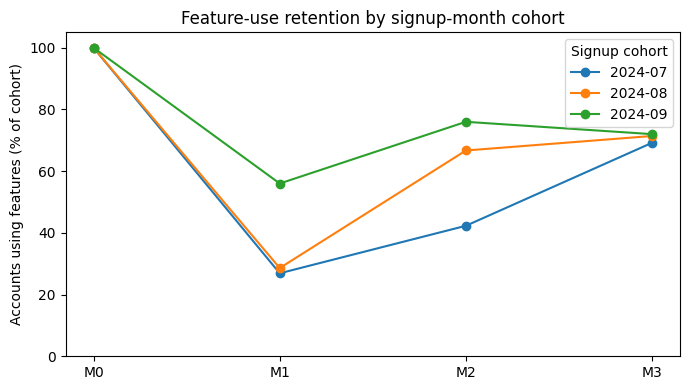

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
for cohort, row in retention.iterrows():
    ax.plot(["M0", "M1", "M2", "M3"], row.values, marker="o", label=str(cohort))
ax.set_title("Feature-use retention by signup-month cohort")
ax.set_ylabel("Accounts using features (% of cohort)")
ax.set_ylim(0, 105)
ax.legend(title="Signup cohort")
plt.tight_layout()
plt.show()

### 서술 답안

**Q1.** 세 코호트 모두 M3 월말(7월→10월 말, 8월→11월 말, 9월→12월 말)이 분석 종료일(2024-12-31) 이전이라, M1~M3 모두 실제로 관찰된 값입니다.

| 코호트 | 가입 계정 | M1 사용(리텐션) | M2 사용(리텐션) | M3 사용(리텐션) |
|---|---:|---:|---:|---:|
| 2024-07 | 26 | 7 (26.9%) | 11 (42.3%) | 18 (**69.2%**) |
| 2024-08 | 21 | 6 (28.6%) | 14 (66.7%) | 15 (71.4%) |
| 2024-09 | 25 | 14 (56.0%) | 19 (76.0%) | 18 (**72.0%**) |

**Q2.** M3 리텐션은 **9월 코호트가 72.0%로 가장 높고, 7월 코호트가 69.2%로 가장 낮습니다.** 차이는 **2.8%p**입니다.
- 계정 수로 바꾸면 한 계정이 약 4%p에 해당합니다(1/25, 1/26). 따라서 2.8%p는 **계정 1개도 안 되는 차이**라서, M3 시점에는 코호트 간 차이가 거의 없다고 봐야 합니다.
- 오히려 차이가 큰 곳은 **M1**입니다. 9월은 56.0%인데 7·8월은 27~29%로, 약 28%p 차이가 납니다.

**Q3.** **"매월 감소한다"는 가설은 맞지 않습니다.**

| 코호트 | M1→M2 | M2→M3 |
|---|---:|---:|
| 2024-07 | +15.4%p | +26.9%p |
| 2024-08 | +38.1%p | +4.7%p |
| 2024-09 | +20.0%p | −4.0%p |

- 세 코호트 모두 M1→M2에서 **증가**했습니다. 흔히 보는 감소 곡선이 아니라, 시간이 지나며 **사용 계정이 늘어나는 패턴**입니다.
- M2→M3는 코호트마다 다릅니다. 7월은 크게 증가(+26.9), 8월은 소폭 증가(+4.7), 9월은 소폭 감소(−4.0)했습니다. 8·9월은 M2~M3에서 70% 안팎으로 **증가 폭이 줄어드는 모습**을 보입니다.
- 그러나 **정착 시점은 확정할 수 없습니다.**
  - M3까지만 관찰했습니다.
  - 코호트 크기가 21~26개라 한두 계정만 바뀌어도 수 %p가 움직입니다.
  - 9월의 −4.0%p는 계정 1개 차이입니다.
  - M4 이후를 관찰해야 70% 부근에서 멈추는지 알 수 있습니다.

**Q4.** 단정할 수 없습니다.
- 9월 코호트의 M1이 높은 것은 "9월에 무언가 개선됐다"는 뜻일 수도 있습니다. 하지만 **다른 설명도 가능**합니다.
  - 코호트 구성이 다를 수 있습니다(산업, 플랜, 유입 경로 비율).
  - 9월 가입자의 M1은 10월입니다. 이 시기의 계절성이나 영업·마케팅 캠페인이 영향을 줬을 수 있습니다.
  - 로그 수집 방식이 바뀌었을 수 있습니다.
  - 표본이 작아 우연한 변동일 수 있습니다.
- 무작위 배정이 없는 코호트 비교로는 **인과를 확정할 수 없습니다.**
- 추가로 확인할 기록
  1. 7~10월 사이 **제품 릴리스·온보딩 변경 기록**(배포 일자)
  2. 같은 시기 **마케팅·영업 캠페인 일정**
  3. 코호트별 `industry`, `plan_tier`, `referral_source`, `is_trial` 구성 비율
  4. 사용 로그의 **수집 방식이 바뀌었는지**(이벤트 정의·트래킹 변경 이력)

---

## 과제 1 — 개선 우선순위와 개선 시나리오

### 상황

필수 분석 결과를 근거로 실행할 개선안 하나를 제안합니다. 목표 지표는 **가입 월 기능 사용 도달률**입니다. 과제는 필수 수준이며 새로운 분석 기법이나 통계 검정을 요구하지 않습니다.

### 수행 사항

1. 아래 후보의 영향 계정 수와 전체 대상 가입 계정 대비 비율을 계산하세요.
   - A: 가입 월에 구독을 시작하지 않은 계정
   - B: 가입 월에 구독을 시작했지만 가입 월 기능 사용까지 도달하지 않은 계정
   - C: M3 리텐션 최저 코호트 중 M3에 사용하지 않은 계정

2. A·B·C를 교안의 네 기준인 **영향 범위, 목표 지표 연관성, 개선 가능성, 검증 용이성**으로 비교하세요. 영향 범위는 계산값을 적고, 나머지는 이유를 서술합니다. 근거 없는 점수나 상·중·하 등급은 요구하지 않습니다. 후보끼리 중복될 수 있으므로 비율을 합산하지 않습니다.

3. 우선순위 1개를 선택하고, 해당 이슈가 어떤 AARRR 단계에 해당하는지 설명하세요. 선정 근거에는 퍼널과 리텐션의 분석 수치를 함께 사용하세요. 이후 이상 신호, 개선안, 기대 효과, A/B 테스트 아이디어를 작성하세요. 개선안에는 "어떤 원인 때문에 문제가 발생하며, 어떤 변경을 하면 목표 지표가 개선될 것이다"라는 검증 가능한 가설을 포함하세요. 기대 효과는 현재 값과 예상 개선폭·목표값을 제시하되 가정임을 밝히세요.

4. A/B 아이디어에는 대상, A의 기존 경험, B의 변경 경험, 양쪽에 동일하게 적용할 비교 지표의 분자·분모·관찰 기간을 적으세요. 실제 실험 수행·유의성 검정은 하지 않습니다.

5. 가설이 지지되지 않았을 때의 대안 또는 실행 방안의 제약 조건을 한 가지 이상 작성하세요. 대안을 선택하면 다음에 무엇을 바꾸거나 확인할지 설명하고, 제약 조건을 선택하면 인력·일정·개발 자원·데이터 확보 등의 조건이 실행에 어떤 영향을 주는지 설명하세요.

### 질문

Q1. 세 후보의 영향 계정 수와 전체 대상 대비 비율은 얼마인가요?

Q2. 네 가지 기준을 적용하면 무엇을 우선하며, 영향 계정 수만으로 결정하면 안 되는 이유는 무엇인가요?

Q3. 선택한 이슈는 어떤 AARRR 단계에 해당하며, 원인 가설과 네 항목의 개선 시나리오는 무엇인가요?

Q4. 제시한 목표값은 관측 결과인가요, 예상인가요? 원인과 효과를 어떻게 구분했나요?

Q5. 가설이 지지되지 않으면 어떤 대안을 검토하겠나요? 또는 실행 시 어떤 제약 조건을 고려해야 하나요? 둘 중 하나를 선택하여 설명하세요.

### 제출물 / 체크 포인트

과제의 계산 코드·출력, 네 기준 비교표, 퍼널·리텐션 수치에 근거한 우선순위와 AARRR 단계, 원인 가설을 포함한 네 항목의 개선 시나리오, 가설이 지지되지 않을 때의 대안 또는 실행 제약 조건, Q1~Q5 답변을 제출합니다. 필수 1·2는 연습용이며, 과제 판단에 사용한 분석 수치는 과제 답안에도 명시하세요. 정답의 우선순위와 달라도 계산과 목표 지표 연결이 타당하고 검증 가능한 시나리오이면 인정합니다.

In [7]:
N = len(signup_ids)

cand_A = signup_ids - sub_ids                       # 가입 월 구독 미시작
cand_B = sub_ids - use_ids                          # 구독 시작했지만 가입 월 미사용
low_cohort = retention["M3"].idxmin()               # M3 리텐션 최저 코호트
low_ids = set(target.loc[target.cohort == low_cohort, "account_id"])
m3_users = set(events.loc[(events.month_offset == 3) & (events.cohort == low_cohort), "account_id"])
cand_C = low_ids - m3_users                         # 최저 코호트 중 M3 미사용

candidates = pd.DataFrame({
    "candidate": ["A", "B", "C"],
    "description": ["가입 월 구독 미시작",
                    "가입 월 구독 시작 → 가입 월 기능 사용 미도달",
                    f"M3 최저 코호트({low_cohort}) 중 M3 미사용"],
    "accounts": [len(cand_A), len(cand_B), len(cand_C)],
})
candidates["share_of_target(%)"] = (candidates["accounts"] / N * 100).round(1)
display(candidates)   # 후보끼리 겹칠 수 있으므로 비율을 합산하지 않습니다.

print("후보 간 중복 계정 수: A∩C =", len(cand_A & cand_C), "/ B∩C =", len(cand_B & cand_C))

# 목표 지표와의 연결: 각 후보가 전부 해결되면 가입 월 도달률에 직접 더해질 수 있는가?
print(f"\n현재 가입 월 기능 사용 도달률: {reach_rate:.1f}% ({len(use_ids)}/{N})")
print("B가 모두 가입 월에 사용하면 최대 도달률:", f"{(len(use_ids) + len(cand_B)) / N * 100:.1f}%")
print("A는 구독 시작과 기능 사용 두 단계를 모두 넘어야 도달률에 반영됨")
print("C는 M3 행동이라 가입 월 도달률(분자)에 직접 반영되지 않음")

,candidate,description,accounts,share_of_target(%)
0,A,가입 월 구독 미시작,20,27.8
1,B,가입 월 구독 시작 → 가입 월 기능 사용 미도달,47,65.3
2,C,M3 최저 코호트(2024-07) 중 M3 미사용,8,11.1


후보 간 중복 계정 수: A∩C = 4 / B∩C = 3

현재 가입 월 기능 사용 도달률: 6.9% (5/72)
B가 모두 가입 월에 사용하면 최대 도달률: 72.2%
A는 구독 시작과 기능 사용 두 단계를 모두 넘어야 도달률에 반영됨
C는 M3 행동이라 가입 월 도달률(분자)에 직접 반영되지 않음


### 서술 답안

**Q1.** 세 후보의 규모는 다음과 같습니다(분모 = 대상 가입 계정 72개).

| 후보 | 정의 | 영향 계정 | 전체 대비 |
|---|---|---:|---:|
| A | 가입 월 구독 미시작 | 20 | 27.8% |
| B | 가입 월 구독 시작 → 가입 월 기능 사용 미도달 | **47** | **65.3%** |
| C | M3 최저 코호트(2024-07) 중 M3 미사용 | 8 | 11.1% |

- 후보끼리 겹칩니다. C의 8개 중 4개는 A, 3개는 B에도 속합니다. 그래서 비율을 더하지 않습니다.

**Q2.** 네 기준으로 비교하면 **B를 우선**합니다.

| 기준 | A: 구독 미시작 | B: 구독 후 가입 월 미사용 | C: 7월 코호트 M3 미사용 |
|---|---|---|---|
| **영향 범위** | 20개(27.8%) | **47개(65.3%)** | 8개(11.1%) |
| **목표 지표 연관성** | 간접적입니다. 구독을 시작해도 다음 구간 전환율이 9.6%라, A를 해결해도 도달률 개선은 작습니다. | **직접적**입니다. 도달률의 분자 바로 앞 단계라, 해결한 계정 수만큼 도달률이 오릅니다(최대 6.9% → 72.2%). | 낮습니다. M3 행동이라 **가입 월 도달률에는 반영되지 않습니다.** |
| **개선 가능성** | 구독을 늦게 시작하는 이유가 영업·계약·결제 등 제품 밖 절차일 수 있어, 제품만으로 바꾸기 어렵습니다. | 이미 구독한 계정에게 **제품 안에서** 첫 사용을 안내하는 것은 제품팀이 바로 할 수 있습니다. 결국 69/72 계정이 사용하므로 "쓸 의사"는 있고, **시점을 앞당기는 문제**입니다. | M3 리텐션은 코호트 간 차이가 2.8%p(계정 1개 미만)로 작고, 7월 코호트도 M1→M3로 오르고 있어 개선할 문제가 뚜렷하지 않습니다. |
| **검증 용이성** | 구독 전환은 계약 주기에 따라 달라 관찰 기간이 길고 결과가 흩어집니다. | 구독 시작 시점에 계정 단위로 무작위 배정할 수 있고, **가입 월 안(수 주)** 에 결과가 나와 검증 주기가 짧습니다. | 결과를 보려면 3개월 이상 기다려야 하고, 대상이 8개뿐이라 비교하기 어렵습니다. |

- **영향 계정 수만으로 결정하면 안 되는 이유**
  - 계정이 많아도 목표 지표와 연결되지 않으면 해결해도 지표가 움직이지 않습니다(C처럼 가입 월 도달률에 반영되지 않는 경우).
  - 원인이 제품 밖에 있으면 개선이 어렵습니다(A처럼).
  - 결과를 확인할 수 없으면 개선했는지조차 판단할 수 없습니다.
  - 이번에는 B가 영향 범위에서도 1위지만, 선정 근거는 **네 기준 모두에서 가장 유리하다는 점**입니다.

**Q3.** 선택한 이슈는 **B: 구독을 시작했지만 가입 월에 기능을 사용하지 않은 계정**입니다.

- **AARRR 단계: Activation(활성화)**
  - 구독 시작은 서비스에 들어온 단계(Acquisition 이후)입니다.
  - 실제 **기능 사용**은 사용자가 제품의 핵심 가치를 처음 경험하는 행동입니다. 교안에서도 Activation은 단순 조회가 아니라 "핵심 가치 행동"(예: 학습 시작)으로 정의했습니다.
  - 따라서 구독 시작 → 첫 기능 사용 사이의 이탈은 Activation 문제입니다.

- **선정 근거 수치**
  - 퍼널: 구독 시작 → 기능 사용 전환율 **9.6%**(52 → 5)로 가장 낮은 구간이고, 미도달 **47개**입니다. 가입 월 도달률은 **6.9%** 에 그칩니다.
  - 리텐션: M1 리텐션 26.9~56.0%, M3 리텐션 69.2~72.0%입니다. 72개 중 69개가 관찰 기간 안에 결국 사용합니다. 즉 **가치 부족보다 첫 사용이 1~2개월 늦어지는 것**이 핵심입니다.

- **개선 시나리오 (네 항목)**

| 항목 | 내용 |
|---|---|
| **① 이상 신호** | 가입 월에 구독을 시작한 52개 계정 중 5개(9.6%)만 가입 월 안에 기능을 썼습니다. 반면 M1~M2에는 첫 사용 계정이 47개로 몰려, **구독 후 첫 사용까지 1~2개월 지연**이 나타납니다. (관찰된 사실) |
| **② 개선안(원인 가설 포함)** | **가설**: "구독을 시작한 직후 무엇부터 해야 하는지 안내가 없어 첫 기능 사용이 다음 달 이후로 미뤄진다. 구독 시작 직후 **첫 기능 사용 가이드**(핵심 기능 1개를 바로 실행하는 체크리스트 + 샘플 데이터 + 3일 차 리마인드 메일)를 제공하면 가입 월 기능 사용 도달률이 오를 것이다." |
| **③ 기대 효과(가정)** | 현재 가입 월 도달률은 **6.9%**(5/72)입니다. B 계정 47개 중 약 20%(약 9~10개)가 가입 월 안에 첫 사용하게 된다고 **가정**하면, 도달률은 약 **20%**(14~15/72)가 됩니다. 목표값은 **가입 월 도달률 20%**(+약 13%p)로 둡니다. 이 수치는 실험 전 **예상치**이며 관측 결과가 아닙니다. |
| **④ A/B 테스트 아이디어** | 아래 표 참고 |

**Q3-④ A/B 테스트 아이디어**

| 항목 | 설계 |
|---|---|
| 대상 | 실험 기간 중 **가입 후 가입 월 안에 구독을 시작한 신규 계정** |
| 배정 | **계정 단위** 무작위 배정(0.5 / 0.5)을 구독 시작 시점에 한 번 하고, 실험 내내 고정 |
| A 그룹(기존 경험) | 구독 시작 후 기존 화면 그대로(별도 첫 사용 안내 없음) |
| B 그룹(변경 경험) | 구독 시작 직후 첫 기능 사용 가이드(체크리스트 + 샘플 데이터 + 3일 차 리마인드) |
| 비교 지표 | **가입 월 기능 사용 도달률** |
| 분자 | 해당 구독으로 **가입 월 말일까지** `usage_count > 0` 사용 기록이 있는 고유 계정 수 |
| 분모 | 그룹에 배정된 고유 계정 수(가입 월 구독 시작 계정) |
| 관찰 기간 | 각 계정의 **가입 월 말일까지**. 관찰 일수가 월말 가입 여부에 따라 달라지므로, 보조로 "구독 시작 후 14일 내 첫 사용률"도 두 그룹에 똑같이 계산 |
| 가드레일 | M1 기능 사용 리텐션(가이드가 일시적 사용만 늘리지 않는지), 지원 티켓 수 |

- 두 그룹에 **같은 정의·같은 관찰 기간**을 적용합니다. 이렇게 해야 월말 가입처럼 관찰 일수가 짧은 효과가 한쪽에만 쏠리지 않고, 무작위 배정으로 두 그룹에 고르게 나뉩니다.

**Q4.** 목표값 **20%는 관측 결과가 아니라 예상(가정)** 입니다.
- 관측값은 현재 도달률 6.9%, 구간 전환율 9.6%, 미도달 47개뿐입니다.
- "B 계정 중 20%가 앞당겨 사용한다"는 것은 실험 전에 세운 가정입니다.
- 원인과 효과는 다음과 같이 나눴습니다.
  - **관찰한 사실**: 구독 후 가입 월 사용이 적고, 첫 사용이 M1~M2로 늦다.
  - **원인 가설**: 첫 사용 안내가 없어서 늦어진다. 아직 확인하지 않았습니다.
  - **효과**: 가이드를 제공하면 도달률이 오른다. A/B 테스트로 검증할 대상입니다.
- 코호트 비교나 퍼널만으로는 인과를 확정할 수 없습니다. 그래서 효과는 **무작위 배정 실험의 A/B 차이**로만 판단합니다.

**Q5.** (대안 선택) **가설이 지지되지 않으면 원인을 "안내 부족"이 아닌 다른 쪽에서 찾습니다.**
1. **관찰 기간 문제인지 먼저 확인합니다.**
   - 구독 시작 후 월말까지 남은 기간은 중앙값 8일뿐입니다. 월말 가입자는 관찰 기간이 매우 짧습니다.
   - B 그룹에서 "구독 후 14일 내 첫 사용률"은 올랐는데 달력 월 기준 도달률만 그대로라면, 문제는 제품이 아니라 **지표 정의**에 있습니다.
   - 이 경우 목표 지표를 "가입 후 30일 기능 사용 도달률"로 바꾸는 것을 검토합니다.
2. **도입 준비 기간 가설로 바꿉니다.**
   - B2B SaaS에서는 계약 후 좌석 배정, 연동 설정, 내부 승인 때문에 첫 사용이 늦을 수 있습니다.
   - `seats`, `plan_tier`, `industry`별로 첫 사용 지연 일수를 비교합니다.
   - 좌석 수가 많은(대형) 계정일수록 늦다면, 가이드보다 **초기 설정 지원(온보딩 콜, 연동 템플릿)** 을 다음 개선안으로 시험합니다.
3. **로그 수집 확인**
   - 가입 월 사용이 실제로는 있었는데 트래킹이 늦게 시작됐을 가능성도 있습니다.
   - 계정별 첫 로그 시점과 구독 시작일의 차이 분포를 확인합니다.

---

## 실습 마무리

- **어떤 분석 문제가 있었는가?**
  - 2024년 7~9월 신규 계정 72개는 가입 월에 기능 사용까지 얼마나 도달하고, 이후에도 사용하는지 확인했습니다.
  - 결과적으로 **가입 월 도달률은 6.9%** 로 낮고, 구독 시작 → 기능 사용 구간(9.6%)에서 크게 막혔습니다.
- **어떤 분석적 방법을 적용했는가?**
  - 계정 단위로 중복을 제거한 **시간순 퍼널**(가입 → 가입 월 구독 → 가입 월 사용)을 만들었습니다.
  - 분모를 고정한 **가입 월 코호트 리텐션**(M1~M3)을 계산했고, 계산 전에 관찰 가능 기간도 확인했습니다.
  - 네 기준(영향 범위, 목표 지표 연관성, 개선 가능성, 검증 용이성)으로 **개선 우선순위**를 정했습니다.
- **무엇을 근거로 결론을 내렸는가?**
  - 퍼널에서 가장 낮은 전환율 구간(9.6%, 미도달 47개)을 찾았습니다.
  - 리텐션에서는 M1 26.9~56.0%에서 M3 약 70%로 **사용이 늘어나는 패턴**을 봤고, 72개 중 69개가 결국 사용한다는 점도 확인했습니다.
  - 이 두 근거를 합쳐 문제를 "가치 부족"이 아닌 **Activation 지연**으로 좁혔습니다. 원인은 가설로 남겨 두고 A/B 테스트로 검증하도록 설계했습니다.